# 04 — Credit curves, CVA and sensitivities

**Question 5 of the project:** what is the discounted expected loss from that exposure, once it is combined with default probabilities and recovery?

1. Turn each counterparty's assumed CDS-equivalent spread and recovery into a hazard rate, survival curve and default probabilities.
2. Combine those with the discounted Expected Exposure to get unilateral CVA, netted and gross, by time bucket.
3. Check the discounting choice, the credit-triangle approximation and credit sensitivities.
4. Measure sensitivity to rate volatility, mean reversion, portfolio tenor and notional, and show Monte Carlo convergence.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
%matplotlib inline

from src.config import (BASE_SIMULATION, CHUNK_SEED_STRIDE, CONVERGENCE_PATHS, COUNTERPARTIES_FILE, CURVE_FILE,
                        HW_PARAMS, MATURITY_SCALES, MEAN_REVERSION_GRID, NOTIONAL_SCALES, PORTFOLIO_FILE,
                        RECOVERY_GRID, SIGMA_GRID, SPREAD_GRID_BP)
from src.credit import credit_curve_table, load_counterparties
from src.curves import load_treasury_curve
from src.cva import aggregate_buckets, cva_by_bucket, discounted_ee, estimate_cva
from src.exposure import gross_exposure, netted_exposure, netting_set_horizons
from src.instruments import load_portfolio
from src.plotting import (plot_convergence, plot_credit_curves, plot_credit_sensitivity, plot_cva_contributions,
                          plot_market_sensitivity, plot_sensitivity_tornado)
from src.simulation import build_time_grid, revalue_portfolio, simulate_paths
from src.validation import convergence_table, credit_sensitivity_table, market_sensitivity_table, tornado_table

pd.set_option('display.float_format', '{:,.4f}'.format)
curve = load_treasury_curve(CURVE_FILE)
portfolio = load_portfolio(PORTFOLIO_FILE)
grid = build_time_grid(portfolio, step=BASE_SIMULATION.time_step)
paths = simulate_paths(HW_PARAMS, grid, BASE_SIMULATION.n_paths, np.random.default_rng(BASE_SIMULATION.seed))
cube = revalue_portfolio(portfolio, curve, paths)
netted, gross = netted_exposure(cube, portfolio), gross_exposure(cube, portfolio)
credits = load_counterparties(COUNTERPARTIES_FILE)
horizons = netting_set_horizons(portfolio)
curve_df, bank_df = curve.df(grid), paths.discount_factors(curve)

## 1. Default probabilities

Default is the first jump of a Poisson process with intensity $\lambda$ (a reduced-form model). With a flat spread $s$ and recovery $R$, the **credit-triangle approximation** gives $\lambda \approx s/(1-R)$: the spread pays for the expected loss rate $\lambda \cdot LGD$. It ignores premium accrual, discounting inside the CDS legs and the spread term structure, so it is an approximation, not a calibration to a CDS curve.

$$S(t) = e^{-\lambda t},\qquad PD(t) = 1 - S(t),\qquad \Delta PD_i = S(t_{i-1}) - S(t_i),\qquad LGD = 1-R$$

The spreads are assumed counterparty spread scenarios (CDS-equivalent) in `data/reference_inputs/counterparties.csv`, not market quotes. Hazards are deterministic and independent of rates, which means no wrong-way risk.

In [2]:
pd.DataFrame([{'netting_set': ns, 'counterparty': c.counterparty_id, 'assumed spread (bp)': c.spread * 1e4,
               'recovery': c.recovery, 'hazard λ': c.hazard, 'LGD': c.lgd,
               f'PD to last maturity': float(c.hazard_curve().cumulative_pd(horizons[ns]))}
              for ns, c in credits.items()])

,netting_set,counterparty,assumed spread (bp),recovery,hazard λ,LGD,PD to last maturity
0,NS_A,CPTY_A,150.0000,0.4000,0.0250,0.6000,0.2212
1,NS_B,CPTY_B,300.0000,0.4000,0.0500,0.6000,0.3297


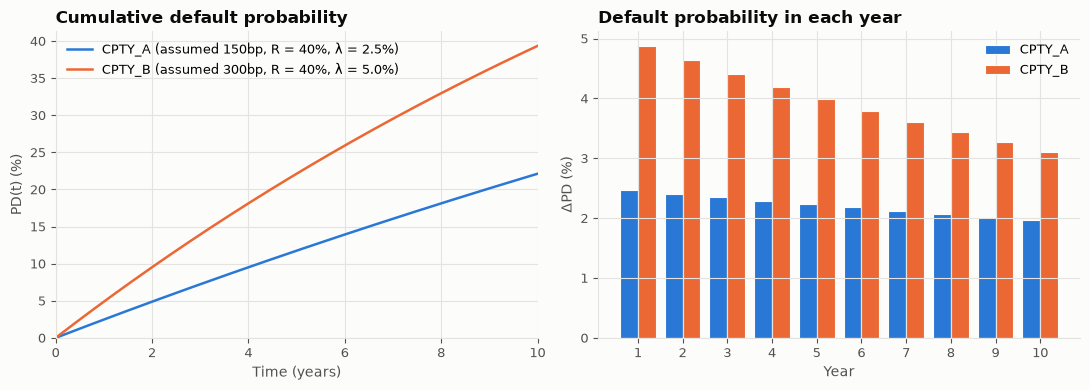

In [3]:
fig = plot_credit_curves(credits, horizon=10.0)

Each year's default probability shrinks slowly because it is conditional on surviving to that year: $\Delta PD_i = e^{-\lambda t_{i-1}}(1-e^{-\lambda\Delta t})$.

## 2. CVA

$$\text{CVA} = LGD \int_0^T E\big[D(0,t)\,E(t)\big]\, dPD(t) \;\approx\; LGD \sum_i \tfrac12\big[dEE_{i-1} + dEE_i\big]\,\Delta PD_i,\qquad dEE(t) = E\big[D(0,t)\,E(t)\big]$$

- **Headline:** each path is discounted with its own simulated bank account $D(0,t)$, because exposure and discount factors are correlated under stochastic rates. The spec §7 version, $P(0,t)\cdot EE(t)$, is kept as a benchmark (section 4).
- **Time grid:** the sum runs over every interval of the 121-date simulation grid (monthly plus every cash-flow date). The yearly buckets in section 3 only regroup those interval contributions.
- **Standard error:** the estimator is linear in exposure, so CVA is the average of a per-path CVA, which gives the standard error directly.

In [4]:
rows = []
for ns, c in credits.items():
    mpd = c.hazard_curve().marginal_pd(grid)
    net = estimate_cva(netted[ns], bank_df, mpd, c.lgd)
    grs = estimate_cva(gross[ns], bank_df, mpd, c.lgd)
    rows.append({'netting_set': ns, 'CVA netted': net.value, 'std error': net.std_error,
                 '95% CI low': net.ci95[0], '95% CI high': net.ci95[1],
                 'CVA gross': grs.value, 'netting reduction': 1 - net.value / grs.value})
summary = pd.DataFrame(rows)
summary.style.format({c: '{:,.0f}' for c in summary.columns[1:-1]} | {'netting reduction': '{:.1%}'})

,netting_set,CVA netted,std error,95% CI low,95% CI high,CVA gross,netting reduction
0,NS_A,"82,715",208,"82,307","83,122","391,613",78.9%
1,NS_B,"130,591","1,348","127,948","133,234","144,217",9.4%


**Reading the numbers**

- **NS_B has the larger CVA** even though both sets have about the same EPE. Its counterparty's spread is twice as wide (300bp vs 150bp).
- **Netting cuts NS_A's CVA by about 79%** but NS_B's by only about 9%, mirroring the exposure results from Phase C. CVA is linear in exposure, so the netting benefit in EPE carries over almost one-for-one.
- **Monte Carlo error is small relative to CVA**: about 0.25% of CVA for NS_A and 1% for NS_B at 10,000 paths. It is larger for NS_B because its exposure is much more dispersed.

## 3. Where the CVA comes from

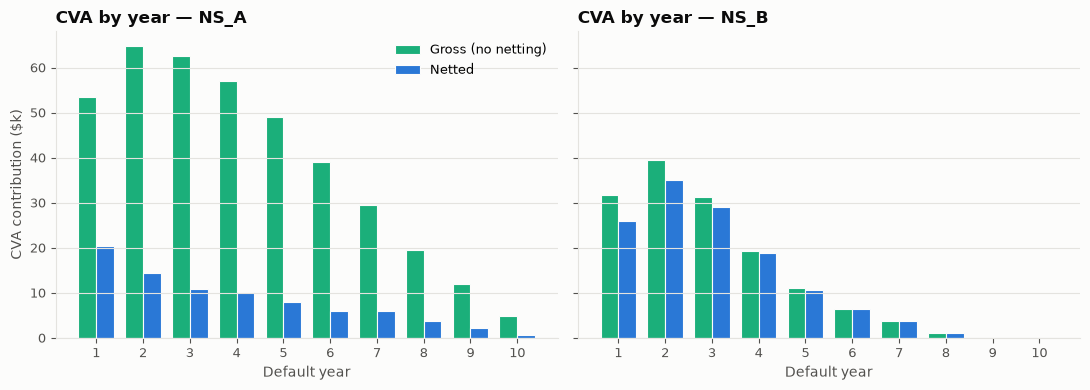

In [5]:
edges = np.arange(0.0, 11.0)
yearly_net, yearly_gross = {}, {}
for ns, c in credits.items():
    mpd = c.hazard_curve().marginal_pd(grid)
    yearly_net[ns] = aggregate_buckets(grid, cva_by_bucket(discounted_ee(netted[ns], bank_df), mpd, c.lgd), edges)
    yearly_gross[ns] = aggregate_buckets(grid, cva_by_bucket(discounted_ee(gross[ns], bank_df), mpd, c.lgd), edges)
fig = plot_cva_contributions(edges, yearly_net, yearly_gross)

In [6]:
pd.DataFrame({f'{ns} netted ($k)': v / 1e3 for ns, v in yearly_net.items()},
             index=[f'year {int(e) + 1}' for e in edges[:-1]]).round(1).T

,year 1,year 2,year 3,year 4,year 5,year 6,year 7,year 8,year 9,year 10
NS_A netted ($k),20.5000,14.5000,10.8000,10.2000,8.1000,6.1000,6.1000,3.7000,2.2000,0.7000
NS_B netted ($k),25.8000,34.9000,29.0000,18.9000,10.6000,6.4000,3.7000,1.2000,0.0000,0.0000


Each bucket's contribution is (discounted EE) × (chance of defaulting in that bucket) × LGD. NS_B's CVA is concentrated in years 1–3, where its exposure peaks. NS_A's falls steadily because its exposure decays from day one. Later years also carry less weight because they are discounted and because the counterparty must first survive to reach them.

## 4. Robustness checks

### Pathwise discounting (headline) vs curve discounting (benchmark)

The headline uses $E[D(0,t)E(t)]$; the spec §7 benchmark uses $P(0,t)\,E[E(t)]$. Since $E[D(0,t)] = P(0,t)$, the difference is exactly the covariance between the discount factor and exposure. With $\sigma = 0$ the two coincide (tested).

In [7]:
rows = []
for ns, c in credits.items():
    mpd = c.hazard_curve().marginal_pd(grid)
    bank_cva = estimate_cva(netted[ns], bank_df, mpd, c.lgd).value
    curve_cva = estimate_cva(netted[ns], curve_df, mpd, c.lgd).value
    triangle = c.spread * np.trapezoid(discounted_ee(netted[ns], bank_df), grid)
    rows.append({'netting_set': ns, 'headline (pathwise D)': bank_cva, 'benchmark (curve DF)': curve_cva,
                 'benchmark vs headline': curve_cva / bank_cva - 1, 'credit triangle s·∫dEE dt': triangle,
                 'triangle vs headline': triangle / bank_cva - 1})
pd.DataFrame(rows).style.format({'headline (pathwise D)': '{:,.0f}', 'benchmark (curve DF)': '{:,.0f}',
                                 'benchmark vs headline': '{:+.1%}', 'credit triangle s·∫dEE dt': '{:,.0f}',
                                 'triangle vs headline': '{:+.1%}'})

,netting_set,headline (pathwise D),benchmark (curve DF),benchmark vs headline,credit triangle s·∫dEE dt,triangle vs headline
0,NS_A,"82,715","83,974",+1.5%,"89,505",+8.2%
1,NS_B,"130,591","134,015",+2.6%,"147,926",+13.3%


- **The curve-DF benchmark overstates CVA by 1.5–2.6%.** These books mostly gain when rates rise, so exposure is largest exactly when the bank-account discount factor is smallest. The deterministic benchmark misses that negative covariance.
- **The credit-triangle shortcut** $\text{CVA} \approx s\int dEE\,dt$ overstates CVA by about 8–13%. It treats the counterparty as defaulting at rate $\lambda$ forever and ignores that it must first survive, a factor $e^{-\lambda t}$ that matters more for the riskier CPTY_B.

### Credit sensitivities (exposures held fixed)

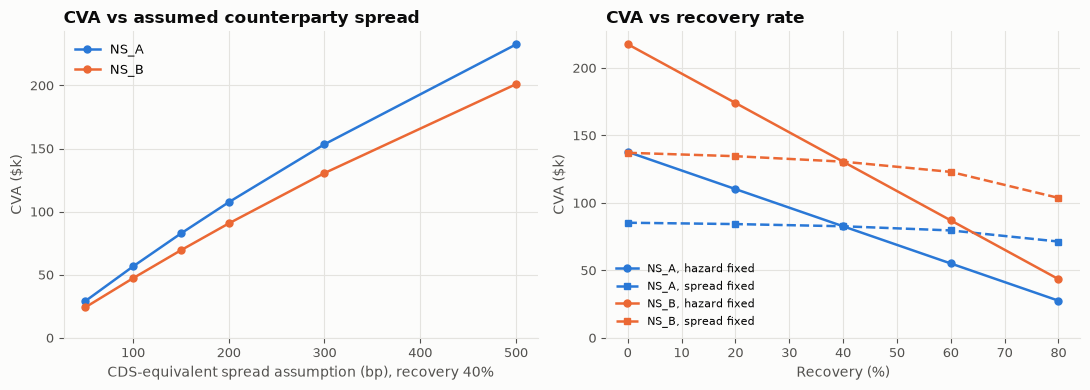

In [8]:
sensitivity = credit_sensitivity_table(grid, netted, bank_df, credits, SPREAD_GRID_BP, RECOVERY_GRID)
fig = plot_credit_sensitivity(sensitivity)

In [9]:
sensitivity.pivot_table(index=['view', 'input'], columns='netting_set_id', values='cva').round(0)

netting_set_id                         NS_A         NS_B
view                  input                             
recovery_hazard_fixed 0.0000   137,858.0000 217,652.0000
                      0.2000   110,286.0000 174,121.0000
                      0.4000    82,715.0000 130,591.0000
                      0.6000    55,143.0000  87,061.0000
                      0.8000    27,572.0000  43,530.0000
recovery_spread_fixed 0.0000    85,330.0000 137,157.0000
                      0.2000    84,334.0000 134,640.0000
                      0.4000    82,715.0000 130,591.0000
                      0.6000    79,622.0000 123,003.0000
                      0.8000    71,388.0000 103,734.0000
spread                50.0000   29,049.0000  24,136.0000
                      100.0000  56,590.0000  47,267.0000
                      150.0000  82,715.0000  69,436.0000
                      200.0000 107,510.0000  90,687.0000
                      300.0000 153,424.0000 130,591.0000
                      500.0000 232,491.0000 201,026.0000

- **Spread:** CVA rises with the assumed spread, slightly less than proportionally. At high spreads the counterparty is less likely to survive to the later, still-exposed years.
- **Recovery, hazard fixed:** only LGD changes, so CVA is exactly proportional to $1-R$. This is the spec's "higher recovery → lower CVA" check.
- **Recovery, spread fixed:** the hazard is re-implied as $s/(1-R)$, so $LGD\times\lambda \approx s$ stays roughly constant and CVA barely moves. It falls a little because a higher hazard means more survival decay. When CVA is calibrated to a CDS spread, the recovery assumption matters far less than it appears to.

## 5. Market and portfolio sensitivities

Each run re-simulates with the base seed (**common random numbers**), so differences reflect the input, not Monte Carlo noise. A σ change reuses exactly the same shocks. For tenor, every trade's tenor is stretched and the trade is re-struck at par plus its original offset, so moneyness does not change. Notional scaling is exact because values are linear in notional.

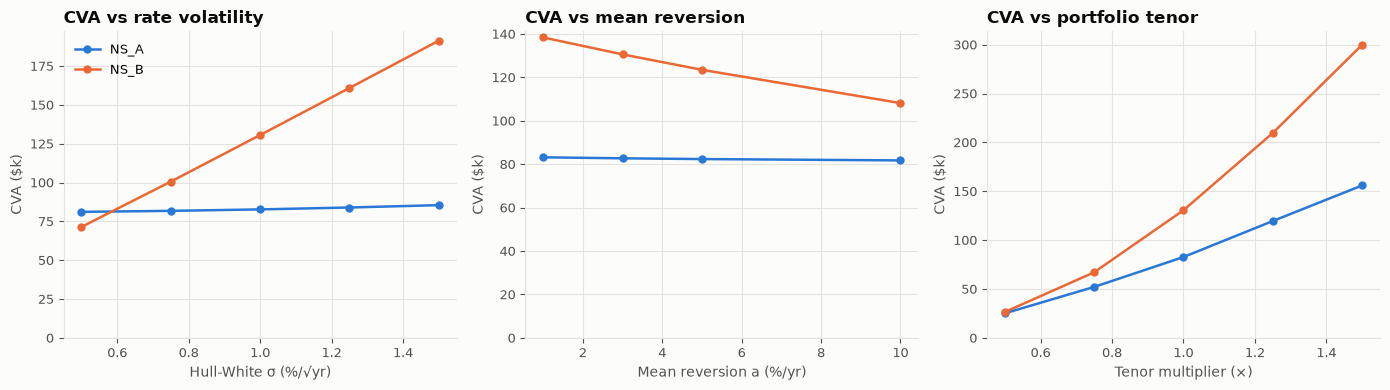

In [10]:
market = market_sensitivity_table(curve, portfolio, credits, HW_PARAMS, BASE_SIMULATION, SIGMA_GRID,
                                  MEAN_REVERSION_GRID, MATURITY_SCALES, NOTIONAL_SCALES)
fig = plot_market_sensitivity(market)

In [11]:
(market.pivot_table(index=['parameter', 'value'], columns='netting_set_id', values='cva') / 1e3).round(1)

netting_set_id            NS_A     NS_B    TOTAL
parameter      value                            
maturity_scale 0.5000  25.1000  26.5000  51.6000
               0.7500  52.1000  67.1000 119.2000
               1.0000  82.7000 130.6000 213.3000
               1.2500 119.6000 209.6000 329.2000
               1.5000 155.9000 299.9000 455.8000
mean_reversion 0.0100  83.2000 138.4000 221.5000
               0.0300  82.7000 130.6000 213.3000
               0.0500  82.4000 123.5000 205.8000
               0.1000  81.8000 108.2000 189.9000
notional_scale 0.5000  41.4000  65.3000 106.7000
               1.0000  82.7000 130.6000 213.3000
               1.5000 124.1000 195.9000 320.0000
               2.0000 165.4000 261.2000 426.6000
sigma          0.0050  81.1000  71.4000 152.6000
               0.0075  81.8000 100.6000 182.4000
               0.0100  82.7000 130.6000 213.3000
               0.0125  83.9000 160.9000 244.8000
               0.0150  85.5000 191.4000 276.8000

- **Rate volatility:** NS_B's CVA rises almost linearly with σ because its exposure is option-like. NS_A barely moves because most of its exposure is value it already holds today, not volatility.
- **Mean reversion:** a higher $a$ damps long-dated rate variance, so NS_B's CVA falls. NS_A is again insensitive.
- **Portfolio tenor:** the strongest market effect, and convex. Longer trades are exposed for longer and to larger rate moves, so CVA grows faster than the tenor multiplier.

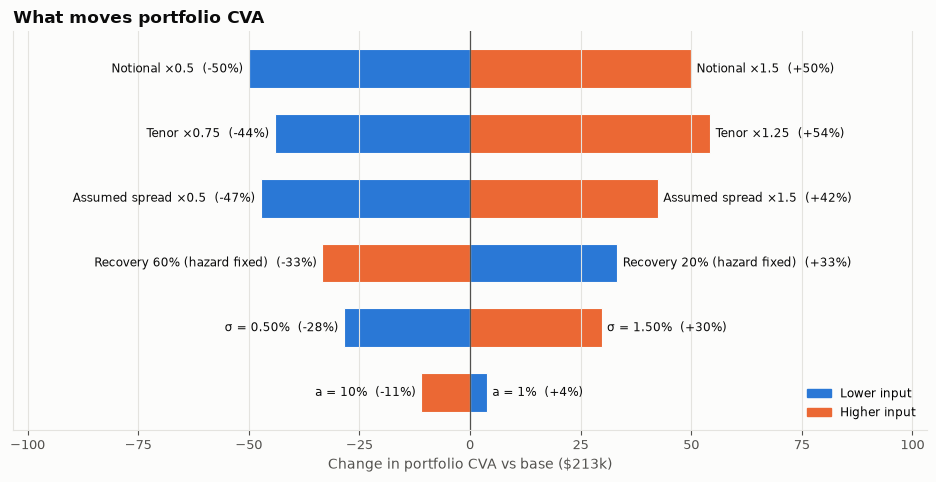

In [12]:
tornado = tornado_table(market, grid, netted, bank_df, credits)
fig = plot_sensitivity_tornado(tornado)

Notional moves CVA one-for-one by construction. Among the real modelling inputs, portfolio tenor and the assumed spread have the widest ranges, then recovery (hazard fixed) and rate volatility; mean reversion matters least.

## 6. Monte Carlo convergence

Independent chunks of 10,000 paths are pooled; chunk 0 is the base case, so the 10,000-path point is the headline exactly. The standard error should fall like $1/\sqrt{N}$.

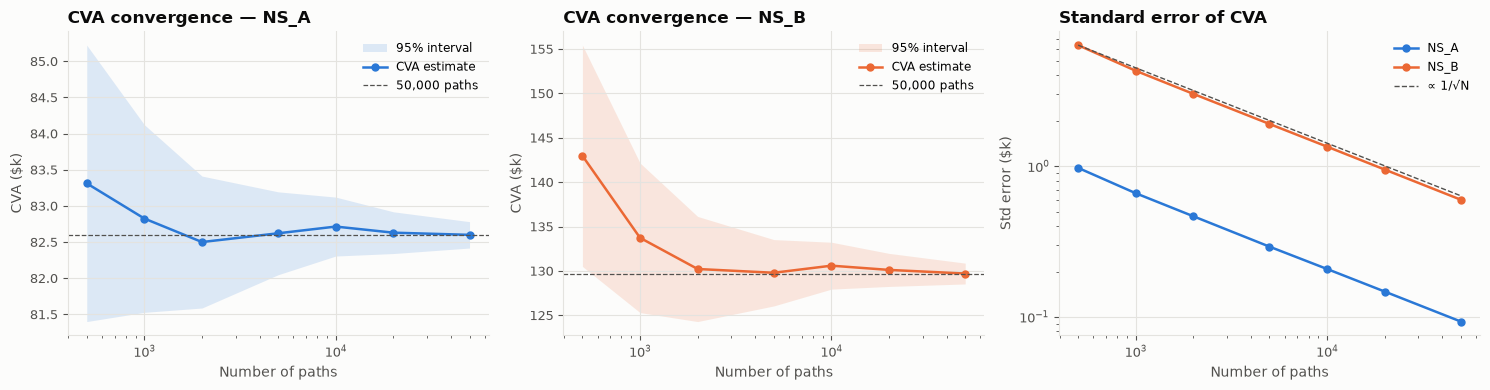

In [13]:
convergence = convergence_table(curve, portfolio, credits, HW_PARAMS, BASE_SIMULATION, CONVERGENCE_PATHS, CHUNK_SEED_STRIDE)
fig = plot_convergence(convergence)

In [14]:
total = convergence[convergence['netting_set_id'] == 'TOTAL'].set_index('n_paths')
total.assign(rel_se=total['cva_se'] / total['cva'])[['cva', 'cva_se', 'ci95_low', 'ci95_high', 'rel_se']]\
    .style.format({'cva': '{:,.0f}', 'cva_se': '{:,.0f}', 'ci95_low': '{:,.0f}', 'ci95_high': '{:,.0f}', 'rel_se': '{:.2%}'})

,cva,cva_se,ci95_low,ci95_high,rel_se
n_paths,,,,,
500,"226,283","7,220","212,132","240,434",3.19%
1000,"216,557","4,882","206,988","226,125",2.25%
2000,"212,717","3,429","205,997","219,437",1.61%
5000,"212,414","2,164","208,173","216,655",1.02%
10000,"213,306","1,530","210,307","216,305",0.72%
20000,"212,744","1,079","210,629","214,858",0.51%
50000,"212,305",680,"210,972","213,639",0.32%


The estimates settle inside the earlier confidence intervals, and the standard error lies on the $1/\sqrt{N}$ line. The 10,000-path base case is therefore precise to well under 1% of portfolio CVA, which is small next to every sensitivity above.